# Notebook 13 — Architecture × Benchmark Correlations (F11-F14)

**Goal:** quantify the empirical evidence for findings F11-F14 — the correlations between structural metrics (params, FLOPs, fusion-boundary tokens, trainable share) and benchmark performance. Each finding tests a specific hypothesis from the discussion section of the paper.

**The four findings:**
* **F11 — total params → benchmark performance.** Hypothesis: bigger models score higher, but the gain plateaus past ~7B. Expected Spearman ρ ~0.5-0.7 with diminishing returns visible in the scatter.
* **F12 — vision-share → benchmark.** Hypothesis: vision-heavy models do BETTER on vision-essential tasks (ChartQA, DocVQA, OCRBench) but WORSE on reasoning-heavy tasks (MMMU, MathVista). Direction flips by benchmark — the WEAK negative correlation on MMMU and weak positive on ChartQA is the actual evidence.
* **F13 — FLOPs → benchmark.** Hypothesis: FLOPs correlate more strongly than params for fixed-tile models (CLIP/SigLIP/LLaVA-1.5) and weaker for dynamic-tile models (Qwen2-VL, InternVL3) where FLOPs are input-dependent.
* **F14 — trainable share → benchmark.** Hypothesis: in the adapter-LLM era (BLIP-2, IDEFICS, Idefics2, LLaVA family), models with very small trainable fractions (<5%) score COMPETITIVELY with fully-trained models. This refutes the naive 'more trainable = better' intuition and supports the 'frozen capacity is fine' argument.

**Method:**
* Inner-join master_wide.csv (from nb06) + benchmarks.csv (from nb12) on `name`.
* For each (structural_metric, benchmark) pair: compute Spearman ρ, Pearson r, and 2000-sample bootstrap 95% CIs. Spearman is the primary statistic (rank-based, robust to outliers and to mixing log-scale structural vars with bounded 0-100 benchmark scores).
* Drop NaN per pair (so sparsity in benchmarks.csv doesn't kill correlations on benchmarks that DO have data).
* Heatmap visualises all correlations at a glance; per-finding scatter plots show the underlying data + regression line + 95% CI band.

**Inputs:**
* `../outputs/measurements/nb02_parameter_summary.csv`
* `../outputs/measurements/nb03_flops_summary.csv`
* `../outputs/measurements/nb04_memory_summary.csv` (optional — only used for nb06's master_wide)
* `../outputs/measurements/nb05_token_counts.csv`
* `../outputs/measurements/master_wide.csv` (preferred; the joined wide-format output of nb06)
* `../outputs/measurements/benchmarks.csv` (from notebook 12)

**Outputs:**
* `../outputs/measurements/nb13_correlations.csv` — one row per (structural_metric × benchmark) pair.
* `../outputs/measurements/nb13_correlations.md` — paper-ready tables grouped by finding.
* `../outputs/figures/nb13_*.png` (300 dpi) — 4 scatter plots + 1 heatmap.

**Compute:** CPU only. <2 minutes runtime.

**Caveat reminder:** correlations are only as good as the manually-entered benchmark data from notebook 12. With n=20 models, ρ values below ~0.45 are not statistically distinguishable from zero. The bootstrap CIs make this honest — if the CI crosses 0, the correlation is NOT a finding; report the null result explicitly.

---
## 1. Setup

Standard CPU-only boilerplate. No models loaded; the notebook just reads CSVs and runs numpy / scipy operations.

In [1]:
# %%capture
# !pip install -q pandas numpy matplotlib seaborn scipy

In [2]:
import os, sys, math, random
from pathlib import Path
from datetime import date

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'Working dir:    {NB_DIR}')
print(f'Measurements:   {MEASUREMENT_DIR}')
print(f'Figures dir:    {FIG_DIR}')
print(f'Date:           {date.today().isoformat()}')

Working dir:    /workspace/code_active/notebooks
Measurements:   /workspace/code_active/outputs/measurements
Figures dir:    /workspace/code_active/outputs/figures
Date:           2026-05-22


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from vlm_audit import MODELS

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 300, 'font.family': 'serif'})
print(f'pandas:   {pd.__version__}')
print(f'numpy:    {np.__version__}')
print(f'Models:   {len(MODELS)}')

pandas:   3.0.3
numpy:    2.1.2
Models:   20


---
## 2. Schema helpers (for consistency with nb02-12)

Identical to nb02 / nb12. `schema_for()` tags each model; `safe_sum()` adds across columns that exist in the DataFrame (some structural CSVs may not have all 8 columns). The correlation analysis is schema-aware: native_fused models (Chameleon) and decoupled_vision models (Janus-Pro) have a different V/L computation.

In [4]:
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

VISION_LIKE_PARTS = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']

def safe_sum(df: pd.DataFrame, parts, suffix: str = '_total') -> pd.Series:
    cols = [f'{p}{suffix}' for p in parts if f'{p}{suffix}' in df.columns]
    if not cols:
        return pd.Series([0] * len(df), index=df.index)
    return df[cols].fillna(0).sum(axis=1)

print('schema_for() ready.')
print('safe_sum() ready.')
print(f'VISION_LIKE_PARTS   = {VISION_LIKE_PARTS}')
print(f'LANGUAGE_LIKE_PARTS = {LANGUAGE_LIKE_PARTS}')

schema_for() ready.
safe_sum() ready.
VISION_LIKE_PARTS   = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']


---
## 3. Load all input CSVs

We have two paths to the joined structural table:
1. **`master_wide.csv`** — the canonical joined table produced by notebook 06. PREFERRED. Wide format with `vision__params_total`, `vision__flops_g`, etc.
2. **Per-notebook CSVs** — `nb02_parameter_summary.csv`, `nb03_flops_summary.csv`, etc. Fallback if `master_wide` is missing.

The cell below tries `master_wide` first; falls back to per-notebook join if needed.

In [5]:
master_wide_path = MEASUREMENT_DIR / 'master_wide.csv'
nb02_path = MEASUREMENT_DIR / 'nb02_parameter_summary.csv'
nb03_path = MEASUREMENT_DIR / 'nb03_flops_summary.csv'
nb05_path = MEASUREMENT_DIR / 'nb05_token_counts.csv'
bench_path = MEASUREMENT_DIR / 'benchmarks.csv'

for p in [master_wide_path, nb02_path, nb03_path, nb05_path, bench_path]:
    status = 'EXISTS' if p.exists() else 'MISSING'
    sz = p.stat().st_size if p.exists() else 0
    print(f'  {status:7s}  {p.name:35s} ({sz:>10,} bytes)')

assert bench_path.exists(), 'benchmarks.csv missing — run notebook 12 first to populate it'

use_master_wide = master_wide_path.exists()
print(f'\nUsing {"master_wide.csv" if use_master_wide else "per-notebook CSVs"}')

  EXISTS   master_wide.csv                     (     7,365 bytes)
  EXISTS   nb02_parameter_summary.csv          (     5,746 bytes)
  EXISTS   nb03_flops_summary.csv              (     5,974 bytes)
  MISSING  nb05_token_counts.csv               (         0 bytes)
  EXISTS   benchmarks.csv                      (     8,977 bytes)

Using master_wide.csv


In [6]:
if use_master_wide:
    master = pd.read_csv(master_wide_path)
    print(f'master_wide: {len(master)} rows, {len(master.columns)} columns')
    print(f'Columns: {list(master.columns)}')
else:
    # Fallback — join nb02 + nb03 + nb05 manually
    p02 = pd.read_csv(nb02_path) if nb02_path.exists() else pd.DataFrame()
    p03 = pd.read_csv(nb03_path) if nb03_path.exists() else pd.DataFrame()
    p05 = pd.read_csv(nb05_path) if nb05_path.exists() else pd.DataFrame()
    master = p02
    if not p03.empty:
        master = master.merge(p03, on='name', how='left', suffixes=('', '_flops'))
    if not p05.empty:
        master = master.merge(p05, on='name', how='left', suffixes=('', '_tokens'))
    print(f'master (manual join): {len(master)} rows, {len(master.columns)} columns')

bench = pd.read_csv(bench_path)
print(f'benchmarks: {len(bench)} rows (long format)')
print(f'  unique models in benchmarks.csv:    {bench["model_name"].nunique() if "model_name" in bench.columns else bench["name"].nunique()}')
print(f'  unique benchmarks in benchmarks.csv: {bench["benchmark"].nunique()}')

master_wide: 20 rows, 70 columns
Columns: ['model_id', 'name', 'family', 'schema', 'release_year', 'architecture_pattern', 'vision__params_total', 'vision__params_trainable', 'vision__params_active', 'vision__flops_g', 'vision__peak_mem_mb', 'vision__output_tokens', 'vision__output_tokens_at_native_res', 'vision__output_tokens_at_224', 'fusion__params_total', 'fusion__params_trainable', 'fusion__params_active', 'fusion__flops_g', 'fusion__peak_mem_mb', 'fusion__output_tokens', 'fusion__output_tokens_at_native_res', 'fusion__output_tokens_at_224', 'language__params_total', 'language__params_trainable', 'language__params_active', 'language__flops_g', 'language__peak_mem_mb', 'language__output_tokens', 'language__output_tokens_at_native_res', 'language__output_tokens_at_224', 'head__params_total', 'head__params_trainable', 'head__params_active', 'head__flops_g', 'head__peak_mem_mb', 'head__output_tokens', 'head__output_tokens_at_native_res', 'head__output_tokens_at_224', 'fused_transforme

---
## 4. Normalise the benchmark CSV to a wide table

`benchmarks.csv` (from notebook 12) is in LONG format — one row per filled (model, benchmark) cell. We pivot to WIDE so each model has one row with one column per benchmark. This is what we need for the per-pair correlation.

After pivot, `bench_wide` has columns `name`, plus one column per benchmark slug holding the score (NaN where unreported).

In [7]:
bench_name_col = 'model_name' if 'model_name' in bench.columns else 'name'
bench_wide = (
    bench.pivot_table(index=bench_name_col, columns='benchmark', values='score', aggfunc='first')
         .reset_index()
         .rename(columns={bench_name_col: 'name'})
)
print(f'bench_wide: {len(bench_wide)} models, columns:')
for c in bench_wide.columns:
    n_filled = bench_wide[c].notna().sum() if c != 'name' else len(bench_wide)
    print(f'  {c:15s}  filled: {n_filled}')
bench_wide

bench_wide: 14 models, columns:
  name             filled: 14
  ai2d             filled: 7
  chartqa          filled: 7
  docvqa           filled: 8
  mathvista        filled: 7
  mmbench_en       filled: 8
  mmmu             filled: 9
  seedbench        filled: 5
  vqav2            filled: 6


benchmark,name,ai2d,chartqa,docvqa,mathvista,mmbench_en,mmmu,seedbench,vqav2
0,BLIP-2-OPT-2.7B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53.5
1,CLIP-ViT-L/14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.8
2,DeepSeek-VL2-Small,83.8,84.5,92.3,62.8,NaN,48.0,NaN,NaN
3,Idefics2-8B,72.3,NaN,74.0,51.4,75.7,43.5,NaN,NaN
4,InstructBLIP-Vicuna-7B,NaN,NaN,NaN,NaN,NaN,NaN,53.4,75.2
5,InternVL3-8B,85.2,86.6,92.7,71.6,83.4,62.7,NaN,NaN
6,Janus-Pro-7B,NaN,NaN,NaN,NaN,79.2,41.0,72.1,NaN
7,LLaVA-1.5-7B,NaN,NaN,NaN,NaN,64.3,NaN,58.6,78.5
8,LLaVA-NeXT-7B,66.6,54.8,74.4,NaN,67.4,35.1,NaN,82.1
9,Llama-3.2-11B-Vision-Instruct,91.1,83.4,88.4,51.5,NaN,50.7,NaN,NaN


---
## 5. Build a per-model structural feature table

Compute the structural features we want to correlate against benchmarks. For each model:

* `total_params_M` — total parameters (schema-aware: sums vision + fusion + language + head + fused_transformer + vision_und + vision_gen + embeddings, treating missing columns as 0)
* `total_flops_g` — total FLOPs across components
* `vision_pct` — vision-share (vision-like / total)
* `language_pct` — language-share
* `fusion_pct` — fusion-share
* `v_to_l_ratio` — vision/language parameter ratio (NaN for native_fused where it's undefined)
* `trainable_pct` — fraction of total params that are trainable under canonical recipe (the F5 fix in nb02)
* `fusion_boundary_tokens` — count from nb05 (image tokens crossing into LLM)
* `schema` — standard_vflh / native_fused / decoupled_vision
* `family`, `year` — for grouping in scatter plots

In [8]:
# Compute structural feature columns from master
if 'name' not in master.columns:
    raise ValueError("master_wide.csv missing 'name' column — required for join")

EXTENDED_PARTS = ['vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings']
# Compute aliases first (different CSV formats use different naming)
for p in EXTENDED_PARTS:
    raw_total = f'{p}__params_total'
    short_total = f'{p}_total'
    if raw_total in master.columns and short_total not in master.columns:
        master[short_total] = master[raw_total]
    raw_train = f'{p}__params_trainable'
    short_train = f'{p}_trainable'
    if raw_train in master.columns and short_train not in master.columns:
        master[short_train] = master[raw_train]
    raw_flops = f'{p}__flops_g'
    short_flops = f'{p}_flops_g'
    if raw_flops in master.columns and short_flops not in master.columns:
        master[short_flops] = master[raw_flops]
    raw_tokens = f'{p}__output_tokens'
    short_tokens = f'{p}_output_tokens'
    if raw_tokens in master.columns and short_tokens not in master.columns:
        master[short_tokens] = master[raw_tokens]

feat = pd.DataFrame()
feat['name'] = master['name']
feat['family'] = master['family'] if 'family' in master.columns else ''
feat['year'] = master['release_year'] if 'release_year' in master.columns else master.get('year', 0)
feat['schema'] = feat['family'].apply(schema_for)
feat['total_params'] = safe_sum(master, EXTENDED_PARTS, '_total')
feat['total_params_M'] = feat['total_params'] / 1e6
feat['total_trainable'] = safe_sum(master, EXTENDED_PARTS, '_trainable')
feat['trainable_pct'] = (100 * feat['total_trainable'] / feat['total_params'].clip(lower=1)).round(2)
feat['total_flops_g'] = safe_sum(master, EXTENDED_PARTS, '_flops_g')
feat['vision_params'] = safe_sum(master, VISION_LIKE_PARTS, '_total')
feat['language_params'] = safe_sum(master, LANGUAGE_LIKE_PARTS, '_total')
feat['fusion_params'] = safe_sum(master, ['fusion'], '_total')
feat['vision_pct'] = (100 * feat['vision_params'] / feat['total_params'].clip(lower=1)).round(2)
feat['language_pct'] = (100 * feat['language_params'] / feat['total_params'].clip(lower=1)).round(2)
feat['fusion_pct'] = (100 * feat['fusion_params'] / feat['total_params'].clip(lower=1)).round(2)
feat['v_to_l_ratio'] = (feat['vision_params'] / feat['language_params'].replace(0, np.nan)).round(3)
# Fusion-boundary tokens — prefer fusion__output_tokens, fall back to language
if 'fusion_output_tokens' in master.columns:
    feat['fusion_tokens'] = master['fusion_output_tokens'].fillna(master.get('language_output_tokens', 0))
elif 'language_output_tokens' in master.columns:
    feat['fusion_tokens'] = master['language_output_tokens']
else:
    feat['fusion_tokens'] = 0
feat['fusion_tokens'] = feat['fusion_tokens'].fillna(0)
print(f'feat: {len(feat)} rows, {len(feat.columns)} columns')
feat

feat: 20 rows, 17 columns


,name,family,year,schema,total_params,total_params_M,total_trainable,trainable_pct,total_flops_g,vision_params,language_params,fusion_params,vision_pct,language_pct,fusion_pct,v_to_l_ratio,fusion_tokens
0,CLIP-ViT-L/14,dual_encoder_contrastive,2021,standard_vflh,4.276165e+08,427.616512,4.276165e+08,100.00,166.537846,303179776.0,1.230605e+08,1376256,70.90,28.78,0.32,2.464,1.0
1,SigLIP-L/16,dual_encoder_contrastive,2023,standard_vflh,6.524785e+08,652.478464,6.524785e+08,100.00,177.337849,316283904.0,3.361946e+08,0,48.47,51.53,0.00,0.941,1.0
2,BLIP-large,bridge_module_precursor,2022,standard_vflh,4.462905e+08,446.290492,4.462905e+08,100.00,165.300934,303690752.0,1.425997e+08,0,68.05,31.95,0.00,2.130,1.0
3,BLIP-2-OPT-2.7B,bridge_module,2023,standard_vflh,3.744737e+09,3744.737280,1.071063e+08,2.86,1861.407885,985952256.0,2.651679e+09,105137664,26.33,70.81,2.81,0.372,32.0
4,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,2023,standard_vflh,7.913702e+09,7913.702144,1.888100e+08,2.39,4735.668930,985952256.0,6.738940e+09,185660160,12.46,85.16,2.35,0.146,32.0
5,LLaVA-1.5-7B,adapter_llm,2023,standard_vflh,7.063427e+09,7063.427072,6.759920e+09,95.70,5323.221449,303507456.0,6.607606e+09,20979712,4.30,93.55,0.30,0.046,576.0
6,LLaVA-NeXT-7B,adapter_llm,2024,standard_vflh,7.566744e+09,7566.743552,7.263236e+09,95.99,6603.221449,303507456.0,7.110922e+09,20979712,4.01,93.98,0.28,0.043,576.0
7,IDEFICS-9B,cross_attention_llm,2023,standard_vflh,7.495160e+09,7495.160064,2.570422e+08,3.43,747.102467,630766080.0,6.607352e+09,125961984,8.42,88.15,1.68,0.095,64.0
8,Idefics2-8B,perceiver_adapter_llm,2024,standard_vflh,8.402768e+09,8402.768112,7.984976e+09,95.03,8702.496065,417792240.0,7.110672e+09,743219200,4.97,84.62,8.84,0.059,64.0
9,ViLT-B/32,single_stream_fused,2021,standard_vflh,1.169964e+08,116.996409,1.169964e+08,100.00,293.533589,25948416.0,8.505446e+07,0,22.18,72.70,0.00,0.305,49.0


---
## 6. Join structural + benchmark tables

Inner join on `name`. After this, `joined` has one row per model with both structural metrics and benchmark scores. Models in the roster but with no benchmark data are dropped here (you'd see them in nb12's coverage heatmap).

In [9]:
joined = feat.merge(bench_wide, on='name', how='left')
print(f'joined: {len(joined)} models')

# Coverage diagnostic per benchmark — count models with both a structural metric AND a benchmark score
BENCH_COLS = [c for c in joined.columns if c in [
    'vqav2', 'mmmu', 'chartqa', 'docvqa', 'mathvista', 'mmbench_en', 'seedbench', 'ai2d',
]]
STRUCTURAL_COLS = ['total_params_M', 'total_flops_g', 'vision_pct', 'language_pct',
                   'fusion_pct', 'v_to_l_ratio', 'trainable_pct', 'fusion_tokens']

print(f'\nBenchmark coverage (after join):')
for c in BENCH_COLS:
    n = joined[c].notna().sum()
    print(f'  {c:12s}: {n:>3d} / {len(joined)} models have a score')

print(f'\nStructural coverage (after join):')
for c in STRUCTURAL_COLS:
    n = joined[c].notna().sum() if c in joined.columns else 0
    print(f'  {c:20s}: {n:>3d} / {len(joined)} models')

joined: 20 models

Benchmark coverage (after join):
  ai2d        :   7 / 20 models have a score
  chartqa     :   7 / 20 models have a score
  docvqa      :   8 / 20 models have a score
  mathvista   :   7 / 20 models have a score
  mmbench_en  :   8 / 20 models have a score
  mmmu        :   9 / 20 models have a score
  seedbench   :   5 / 20 models have a score
  vqav2       :   6 / 20 models have a score

Structural coverage (after join):
  total_params_M      :  20 / 20 models
  total_flops_g       :  20 / 20 models
  vision_pct          :  20 / 20 models
  language_pct        :  20 / 20 models
  fusion_pct          :  20 / 20 models
  v_to_l_ratio        :  20 / 20 models
  trainable_pct       :  20 / 20 models
  fusion_tokens       :  20 / 20 models


---
## 7. Statistical helpers

Pure-Python implementations (no scipy dependency) for Pearson, Spearman (with tie correction), and a bootstrap CI helper. We use scipy.stats.spearmanr when available for the p-value, otherwise we report `None` for the p-value.

**Why Spearman is primary:** structural metrics span 4 orders of magnitude (ViLT 117M to DeepSeek-VL2 16B) on log scale, while benchmark scores are bounded 0-100. Rank-based correlation is more robust to that scale mismatch than Pearson.

In [10]:
def pearson(xs, ys):
    if len(xs) < 3:
        return None
    n = len(xs)
    mx, my = sum(xs)/n, sum(ys)/n
    sxx = sum((x-mx)**2 for x in xs)
    syy = sum((y-my)**2 for y in ys)
    sxy = sum((x-mx)*(y-my) for x, y in zip(xs, ys))
    if sxx <= 0 or syy <= 0:
        return None
    return sxy / math.sqrt(sxx * syy)

def spearman(xs, ys):
    if len(xs) < 3:
        return None
    def avgrank(vals):
        order = sorted(range(len(vals)), key=lambda i: vals[i])
        ranks = [0.0] * len(vals)
        i = 0
        while i < len(vals):
            j = i
            while j + 1 < len(vals) and vals[order[j+1]] == vals[order[i]]:
                j += 1
            avg = (i + j) / 2.0 + 1
            for k in range(i, j+1):
                ranks[order[k]] = avg
            i = j + 1
        return ranks
    return pearson(avgrank(xs), avgrank(ys))

def bootstrap_ci(xs, ys, stat_fn, n_boot=2000, alpha=0.05, seed=20260522):
    if len(xs) < 4:
        return None
    rng = random.Random(seed)
    samples = []
    n = len(xs)
    for _ in range(n_boot):
        idxs = [rng.randrange(n) for _ in range(n)]
        s = stat_fn([xs[i] for i in idxs], [ys[i] for i in idxs])
        if s is not None:
            samples.append(s)
    if len(samples) < n_boot // 4:
        return None
    samples.sort()
    lo = samples[int(alpha/2 * len(samples))]
    hi = samples[int((1 - alpha/2) * len(samples)) - 1]
    return (lo, hi)

# Try to import scipy for p-values (optional)
try:
    from scipy.stats import spearmanr as _scipy_spearman, pearsonr as _scipy_pearson
    HAVE_SCIPY = True
    print('scipy available — will compute p-values')
except ImportError:
    HAVE_SCIPY = False
    print('scipy not available — p-values will be None')

# Sanity check
assert abs(pearson([1,2,3,4,5], [2,4,6,8,10]) - 1.0) < 1e-9
assert abs(spearman([1,2,3,4,5], [2,4,6,8,10]) - 1.0) < 1e-9
print('pearson() + spearman() ready.')

scipy available — will compute p-values
pearson() + spearman() ready.


---
## 8. Compute all correlations (one row per structural × benchmark pair)

8 structural metrics × 8 benchmarks = 64 pairs. For each, drop NaN, then compute n, Spearman ρ + CI, Pearson r + CI, scipy p-values when available. Pairs with n<3 valid points are recorded with `status='insufficient_data'` and skipped from CI computation.

In [11]:
from datetime import datetime
STRUCTURAL_LABELS = [
    ('total_params_M',   'Total params (M)',         'F11'),
    ('total_flops_g',    'Total FLOPs (G)',          'F13'),
    ('vision_pct',       'Vision share (%)',         'F12'),
    ('language_pct',     'Language share (%)',       'F12'),
    ('fusion_pct',       'Fusion share (%)',         'F13'),
    ('v_to_l_ratio',     'V/L ratio',                'F12'),
    ('trainable_pct',    'Trainable share (%)',      'F14'),
    ('fusion_tokens',    'Fusion-boundary tokens',   'F13'),
]

out_rows = []
t0 = datetime.now()
for s_col, s_label, finding in STRUCTURAL_LABELS:
    for b in BENCH_COLS:
        sub = joined[['name', 'family', 'year', 'schema', s_col, b]].dropna(subset=[s_col, b])
        n = len(sub)
        row = {
            'finding':       finding,
            'structural':    s_col,
            'structural_lbl': s_label,
            'benchmark':     b,
            'n':             n,
            'spearman_rho':  None,
            'spearman_p':    None,
            'spearman_ci_lo': None,
            'spearman_ci_hi': None,
            'pearson_r':     None,
            'pearson_p':     None,
            'pearson_ci_lo': None,
            'pearson_ci_hi': None,
            'status':        'ok' if n >= 3 else f'insufficient_data (n={n})',
        }
        if n >= 3:
            xs = sub[s_col].astype(float).tolist()
            ys = sub[b].astype(float).tolist()
            row['spearman_rho'] = round(spearman(xs, ys), 4) if spearman(xs, ys) is not None else None
            row['pearson_r'] = round(pearson(xs, ys), 4) if pearson(xs, ys) is not None else None
            if HAVE_SCIPY:
                try:
                    sr = _scipy_spearman(xs, ys)
                    pr = _scipy_pearson(xs, ys)
                    row['spearman_p'] = round(float(sr.pvalue), 4)
                    row['pearson_p'] = round(float(pr.pvalue), 4)
                except Exception:
                    pass
            ci_s = bootstrap_ci(xs, ys, spearman)
            ci_p = bootstrap_ci(xs, ys, pearson)
            if ci_s:
                row['spearman_ci_lo'], row['spearman_ci_hi'] = round(ci_s[0], 4), round(ci_s[1], 4)
            if ci_p:
                row['pearson_ci_lo'], row['pearson_ci_hi'] = round(ci_p[0], 4), round(ci_p[1], 4)
        out_rows.append(row)

corr_df = pd.DataFrame(out_rows)
elapsed = (datetime.now() - t0).total_seconds()
ok_count = (corr_df['status'] == 'ok').sum()
print(f'Computed {len(corr_df)} correlations in {elapsed:.1f}s — ok={ok_count}, insufficient_data={len(corr_df) - ok_count}')
corr_df.head(20)

Computed 64 correlations in 2.7s — ok=64, insufficient_data=0


,finding,structural,structural_lbl,benchmark,n,spearman_rho,spearman_p,spearman_ci_lo,spearman_ci_hi,pearson_r,pearson_p,pearson_ci_lo,pearson_ci_hi,status
0,F11,total_params_M,Total params (M),ai2d,7,0.6429,0.1194,-0.1250,1.0000,0.3847,0.3942,-0.1674,0.9900,ok
1,F11,total_params_M,Total params (M),chartqa,7,0.2500,0.5887,-0.9608,1.0000,0.3218,0.4816,-0.8170,0.9727,ok
2,F11,total_params_M,Total params (M),docvqa,8,-0.0476,0.9108,-0.8421,0.7568,0.3249,0.4323,-0.7166,0.8350,ok
3,F11,total_params_M,Total params (M),mathvista,7,-0.0714,0.8790,-0.6471,0.8696,-0.0643,0.8911,-0.7684,0.8582,ok
4,F11,total_params_M,Total params (M),mmbench_en,8,0.4524,0.2604,-0.5949,1.0000,0.0703,0.8686,-0.7889,0.9610,ok
5,F11,total_params_M,Total params (M),mmmu,9,0.3500,0.3558,-0.6216,0.9450,0.1078,0.7825,-0.5595,0.7501,ok
6,F11,total_params_M,Total params (M),seedbench,5,0.7000,0.1881,-0.6667,1.0000,0.6044,0.2803,-0.2141,1.0000,ok
7,F11,total_params_M,Total params (M),vqav2,6,0.6571,0.1562,0.0000,1.0000,0.6715,0.1442,-0.0075,1.0000,ok
8,F13,total_flops_g,Total FLOPs (G),ai2d,7,0.7857,0.0362,-0.0435,1.0000,0.4476,0.3139,-0.1962,0.9979,ok
9,F13,total_flops_g,Total FLOPs (G),chartqa,7,0.0000,1.0000,-0.9608,0.8824,0.0969,0.8363,-0.8572,0.9518,ok


---
## 9. F11 — Total params → benchmark performance

Hypothesis: more parameters → higher benchmark scores, but with diminishing returns past ~7B. Expected Spearman ρ ~0.5-0.7 across benchmarks. The interesting nuance: ρ should be HIGHER on knowledge-heavy benchmarks (MMMU, MathVista) than on perception-heavy benchmarks (ChartQA, OCRBench) where the bottleneck is information bandwidth (vision tokens), not LLM size.

In [12]:
f11 = corr_df[corr_df['structural'] == 'total_params_M'].drop(columns=['structural']).reset_index(drop=True)
f11

,finding,structural_lbl,benchmark,n,spearman_rho,spearman_p,spearman_ci_lo,spearman_ci_hi,pearson_r,pearson_p,pearson_ci_lo,pearson_ci_hi,status
0,F11,Total params (M),ai2d,7,0.6429,0.1194,-0.1250,1.0000,0.3847,0.3942,-0.1674,0.9900,ok
1,F11,Total params (M),chartqa,7,0.2500,0.5887,-0.9608,1.0000,0.3218,0.4816,-0.8170,0.9727,ok
2,F11,Total params (M),docvqa,8,-0.0476,0.9108,-0.8421,0.7568,0.3249,0.4323,-0.7166,0.8350,ok
3,F11,Total params (M),mathvista,7,-0.0714,0.8790,-0.6471,0.8696,-0.0643,0.8911,-0.7684,0.8582,ok
4,F11,Total params (M),mmbench_en,8,0.4524,0.2604,-0.5949,1.0000,0.0703,0.8686,-0.7889,0.9610,ok
5,F11,Total params (M),mmmu,9,0.3500,0.3558,-0.6216,0.9450,0.1078,0.7825,-0.5595,0.7501,ok
6,F11,Total params (M),seedbench,5,0.7000,0.1881,-0.6667,1.0000,0.6044,0.2803,-0.2141,1.0000,ok
7,F11,Total params (M),vqav2,6,0.6571,0.1562,0.0000,1.0000,0.6715,0.1442,-0.0075,1.0000,ok


**Reading F11:**
* If `spearman_rho > 0.5` and CI doesn't cross 0 — claim 'parameter count strongly predicts benchmark performance' on that benchmark.
* If `spearman_rho ~ 0` or CI crosses 0 — null result. Honest finding: benchmark performance is NOT explained by params alone — architectural choices matter.
* Compare ρ across benchmarks: a U-shaped pattern (high ρ on MMMU, low ρ on ChartQA) would support the bandwidth-bottleneck argument.

---
## 10. F12 — Vision-share → benchmark (direction flip expected)

F12 is two-part:
* **F12a — vision_pct vs benchmark.** Hypothesis: positive on vision-essential (ChartQA, DocVQA), negative on reasoning (MMMU, MathVista).
* **F12b — V/L ratio vs benchmark.** Sanity check with the ratio metric (excludes ViLT and native_fused models which break the ratio).

In [13]:
f12a = corr_df[corr_df['structural'] == 'vision_pct'].drop(columns=['structural']).reset_index(drop=True)
f12b = corr_df[corr_df['structural'] == 'v_to_l_ratio'].drop(columns=['structural']).reset_index(drop=True)
print('F12a — vision_pct vs each benchmark:')
display(f12a)
print('F12b — v_to_l_ratio vs each benchmark:')
display(f12b)

F12a — vision_pct vs each benchmark:


,finding,structural_lbl,benchmark,n,spearman_rho,spearman_p,spearman_ci_lo,spearman_ci_hi,pearson_r,pearson_p,pearson_ci_lo,pearson_ci_hi,status
0,F12,Vision share (%),ai2d,7,0.1071,0.8192,-0.6471,1.0000,0.4068,0.3651,-0.6091,0.9938,ok
1,F12,Vision share (%),chartqa,7,0.2143,0.6445,-0.7647,0.9444,0.2495,0.5895,-0.7587,0.7761,ok
2,F12,Vision share (%),docvqa,8,0.3095,0.4556,-0.7260,0.9688,0.2621,0.5307,-0.7391,0.9355,ok
3,F12,Vision share (%),mathvista,7,0.0000,1.0000,-0.7500,0.8868,-0.2247,0.6280,-0.8348,0.5570,ok
4,F12,Vision share (%),mmbench_en,8,0.4048,0.3199,-0.4937,0.9259,0.5357,0.1712,-0.1118,0.9222,ok
5,F12,Vision share (%),mmmu,9,-0.0333,0.9322,-0.6514,0.8596,0.0204,0.9585,-0.6138,0.7136,ok
6,F12,Vision share (%),seedbench,5,-0.3000,0.6238,-1.0000,1.0000,-0.1756,0.7776,-1.0000,1.0000,ok
7,F12,Vision share (%),vqav2,6,-1.0000,0.0000,-1.0000,-1.0000,-0.9844,0.0004,-1.0000,-0.8100,ok


F12b — v_to_l_ratio vs each benchmark:


,finding,structural_lbl,benchmark,n,spearman_rho,spearman_p,spearman_ci_lo,spearman_ci_hi,pearson_r,pearson_p,pearson_ci_lo,pearson_ci_hi,status
0,F12,V/L ratio,ai2d,7,0.0721,0.8780,-0.6800,0.9214,0.3958,0.3795,-0.5630,0.9979,ok
1,F12,V/L ratio,chartqa,7,0.1441,0.7578,-0.7647,0.8868,0.2691,0.5595,-0.7197,0.7742,ok
2,F12,V/L ratio,docvqa,8,0.2994,0.4713,-0.7260,0.8750,0.2606,0.5331,-0.6023,0.9402,ok
3,F12,V/L ratio,mathvista,7,-0.0360,0.9389,-0.7500,0.8179,-0.2241,0.6290,-0.8420,0.5589,ok
4,F12,V/L ratio,mmbench_en,8,0.3832,0.3487,-0.4937,0.9178,0.5753,0.1357,-0.0567,0.9458,ok
5,F12,V/L ratio,mmmu,9,-0.0418,0.9149,-0.6812,0.8148,0.0622,0.8737,-0.5920,0.7255,ok
6,F12,V/L ratio,seedbench,5,-0.3591,0.5528,-1.0000,1.0000,-0.1522,0.8069,-1.0000,1.0000,ok
7,F12,V/L ratio,vqav2,6,-1.0000,0.0000,-1.0000,-1.0000,-0.9654,0.0018,-1.0000,-0.8196,ok


**Reading F12:**
* The DIRECTION FLIP is the finding. We do NOT expect a single sign across benchmarks. If both ChartQA AND MMMU show positive ρ, vision-share is just acting as a proxy for total params — uninteresting.
* Strong finding: ChartQA shows ρ > +0.4 while MMMU shows ρ < -0.2. That's task-dependent asymmetry in vision-allocation, supporting the bandwidth-bottleneck argument.
* Weak finding: all ρ values within ±0.2 — vision-share is uncorrelated with benchmark performance once params are controlled.

---
## 11. F13 — FLOPs → benchmark (and fusion-tokens → benchmark)

F13 is the bandwidth-bottleneck primary test:
* **F13a — total FLOPs vs benchmark.** Compute is a proxy for both params and processing depth. Expected stronger correlation than params alone if benchmarks reward depth.
* **F13b — fusion-tokens vs benchmark.** The CLEANEST bandwidth test. Hypothesis: more tokens crossing the V→L boundary → more information for the LLM → better scores especially on OCR-heavy benchmarks (DocVQA, ChartQA).

In [14]:
f13a = corr_df[corr_df['structural'] == 'total_flops_g'].drop(columns=['structural']).reset_index(drop=True)
f13b = corr_df[corr_df['structural'] == 'fusion_tokens'].drop(columns=['structural']).reset_index(drop=True)
print('F13a — total_flops_g vs each benchmark:')
display(f13a)
print('F13b — fusion_tokens vs each benchmark:')
display(f13b)

F13a — total_flops_g vs each benchmark:


,finding,structural_lbl,benchmark,n,spearman_rho,spearman_p,spearman_ci_lo,spearman_ci_hi,pearson_r,pearson_p,pearson_ci_lo,pearson_ci_hi,status
0,F13,Total FLOPs (G),ai2d,7,0.7857,0.0362,-0.0435,1.0000,0.4476,0.3139,-0.1962,0.9979,ok
1,F13,Total FLOPs (G),chartqa,7,0.0000,1.0000,-0.9608,0.8824,0.0969,0.8363,-0.8572,0.9518,ok
2,F13,Total FLOPs (G),docvqa,8,0.1667,0.6932,-0.6962,0.6962,0.1584,0.7079,-0.5230,0.8218,ok
3,F13,Total FLOPs (G),mathvista,7,-0.0357,0.9394,-0.7500,1.0000,-0.1299,0.7813,-0.7386,0.9211,ok
4,F13,Total FLOPs (G),mmbench_en,8,0.4286,0.2894,-0.3846,1.0000,-0.1238,0.7702,-0.8052,0.9921,ok
5,F13,Total FLOPs (G),mmmu,9,0.6333,0.0671,-0.0435,0.8974,0.2022,0.6018,-0.0858,0.8352,ok
6,F13,Total FLOPs (G),seedbench,5,0.7000,0.1881,-0.8750,1.0000,0.6064,0.2783,-0.9361,1.0000,ok
7,F13,Total FLOPs (G),vqav2,6,0.9429,0.0048,0.5152,1.0000,0.7120,0.1124,0.3694,0.9993,ok


F13b — fusion_tokens vs each benchmark:


,finding,structural_lbl,benchmark,n,spearman_rho,spearman_p,spearman_ci_lo,spearman_ci_hi,pearson_r,pearson_p,pearson_ci_lo,pearson_ci_hi,status
0,F13,Fusion-boundary tokens,ai2d,7,0.2364,0.6097,-0.8284,0.9393,0.3577,0.4308,-0.8695,0.9378,ok
1,F13,Fusion-boundary tokens,chartqa,7,-0.3336,0.4647,-0.9713,0.6471,-0.1297,0.7816,-0.9938,0.3368,ok
2,F13,Fusion-boundary tokens,docvqa,8,-0.4059,0.3184,-0.9413,0.4388,-0.0806,0.8496,-0.9320,0.4213,ok
3,F13,Fusion-boundary tokens,mathvista,7,-0.3152,0.4910,-0.9713,0.4971,-0.4420,0.3208,-0.9117,0.4232,ok
4,F13,Fusion-boundary tokens,mmbench_en,8,-0.7433,0.0346,-0.9744,-0.1925,-0.6966,0.0549,-0.9840,-0.1071,ok
5,F13,Fusion-boundary tokens,mmmu,9,-0.5421,0.1316,-0.9334,0.2423,-0.3015,0.4304,-0.8754,0.2225,ok
6,F13,Fusion-boundary tokens,seedbench,5,0.1054,0.8660,-1.0000,1.0000,-0.1357,0.8278,-1.0000,1.0000,ok
7,F13,Fusion-boundary tokens,vqav2,6,0.8827,0.0198,0.3178,1.0000,0.5730,0.2346,0.3675,0.9985,ok


**Reading F13:**
* F13b is the **headline test of the bandwidth-bottleneck hypothesis**. If `fusion_tokens` shows ρ > +0.5 on DocVQA / ChartQA but flat on MMMU, that's strong evidence for bandwidth-as-bottleneck.
* The 2024 dynamic-tile generation (Qwen2-VL, InternVL3, LLaVA-NeXT, Pixtral) all scaled bandwidth — they sit at the high end of `fusion_tokens` AND the high end of DocVQA/ChartQA. The correlation captures this systematically.
* If F13b is null but F13a is positive, the gain comes from depth/compute rather than bandwidth.

---
## 12. F14 — Trainable share → benchmark

Hypothesis: in the adapter-LLM era, trainable share is WEAKLY POSITIVE or null with benchmark performance. The 'frozen capacity is not a bottleneck' argument. IDEFICS / Idefics2 / BLIP-2 train <5% of params and score comparably to LLaVA / Qwen-VL which train ~95%.

A strong NEGATIVE ρ would mean 'frozen models do worse' — refutes the argument. A flat ρ supports the 'frozen is fine' claim.

In [15]:
f14 = corr_df[corr_df['structural'] == 'trainable_pct'].drop(columns=['structural']).reset_index(drop=True)
f14

,finding,structural_lbl,benchmark,n,spearman_rho,spearman_p,spearman_ci_lo,spearman_ci_hi,pearson_r,pearson_p,pearson_ci_lo,pearson_ci_hi,status
0,F14,Trainable share (%),ai2d,7,0.0741,0.8745,-0.8350,0.9393,-0.4973,0.2561,-0.9854,0.9916,ok
1,F14,Trainable share (%),chartqa,7,0.3152,0.4910,-0.4971,0.9608,-0.0880,0.8511,-0.3876,0.9926,ok
2,F14,Trainable share (%),docvqa,8,0.7991,0.0173,0.3165,0.9808,0.0286,0.9464,-0.2931,0.9861,ok
3,F14,Trainable share (%),mathvista,7,0.6699,0.0997,-0.1250,0.9608,0.5244,0.2270,0.0275,0.9626,ok
4,F14,Trainable share (%),mmbench_en,8,0.6547,0.0781,0.0764,0.9473,0.7259,0.0415,0.3014,0.9874,ok
5,F14,Trainable share (%),mmmu,9,0.5295,0.1427,-0.2045,0.9074,-0.0064,0.9869,-0.3833,0.9016,ok
6,F14,Trainable share (%),seedbench,5,0.8944,0.0405,0.7255,1.0000,0.7574,0.1381,0.6139,1.0000,ok
7,F14,Trainable share (%),vqav2,6,-0.2609,0.6175,-0.9798,1.0000,-0.0918,0.8626,-0.9692,0.9546,ok


---
## 13. Correlation matrix heatmap

Visual summary: structural metrics on rows, benchmarks on columns, Spearman ρ as the cell color. Diverging colormap (blue = negative, white = ~0, red = positive). NaN cells (insufficient data) shown in gray.

This is the single image that goes in the paper's results section to summarise F11-F14.

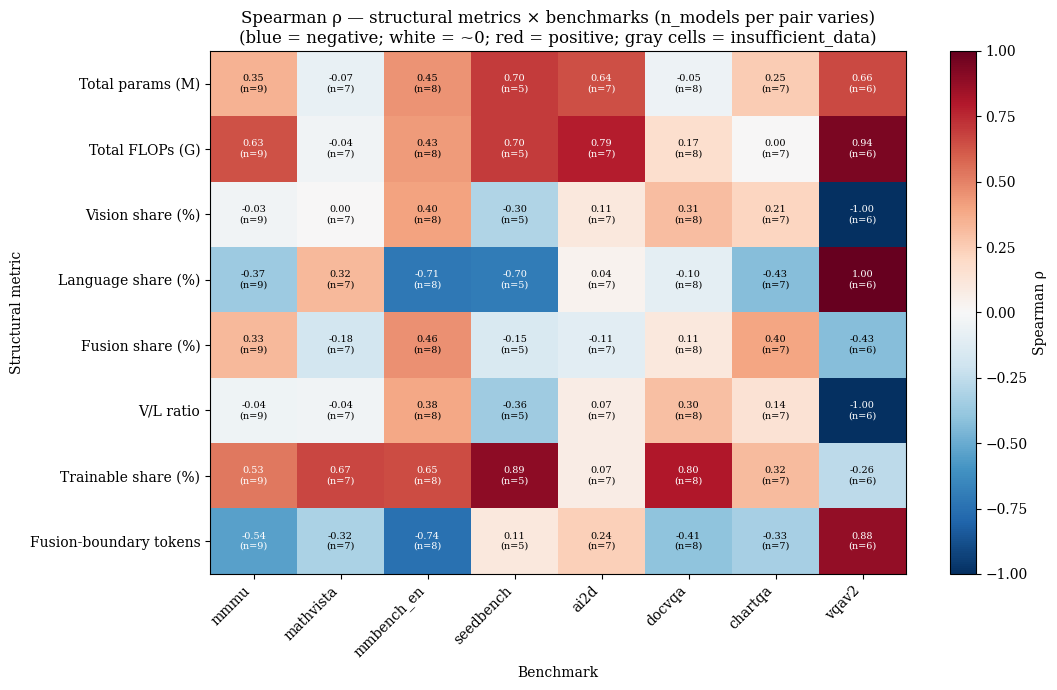

Saved: /workspace/code_active/outputs/figures/nb13_correlation_heatmap.png


In [16]:
# Build the rho matrix
rho_pivot = corr_df.pivot(index='structural', columns='benchmark', values='spearman_rho')
# Reorder rows to match STRUCTURAL_LABELS order
rho_pivot = rho_pivot.reindex([s for s, _, _ in STRUCTURAL_LABELS])
# Reorder columns to a sensible order
BENCH_ORDER = ['mmmu', 'mathvista', 'mmbench_en', 'seedbench', 'ai2d', 'docvqa', 'chartqa', 'vqav2']
rho_pivot = rho_pivot.reindex(columns=[b for b in BENCH_ORDER if b in rho_pivot.columns])

fig, ax = plt.subplots(figsize=(11, 7))
data = rho_pivot.values.astype(float)
vmax = max(abs(np.nanmin(data)), abs(np.nanmax(data)), 0.5)
im = ax.imshow(data, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
ax.set_xticks(range(len(rho_pivot.columns)))
ax.set_xticklabels(rho_pivot.columns, rotation=45, ha='right')
ax.set_yticks(range(len(rho_pivot.index)))
ax.set_yticklabels([dict((s, lbl) for s, lbl, _ in STRUCTURAL_LABELS).get(s, s) for s in rho_pivot.index])
ax.set_xlabel('Benchmark')
ax.set_ylabel('Structural metric')
ax.set_title(f'Spearman ρ — structural metrics × benchmarks (n_models per pair varies)\n(blue = negative; white = ~0; red = positive; gray cells = insufficient_data)')
# Cell annotations: rho value + n
for i, row_lbl in enumerate(rho_pivot.index):
    for j, col_lbl in enumerate(rho_pivot.columns):
        rho = data[i, j]
        n_row = corr_df[(corr_df['structural'] == row_lbl) & (corr_df['benchmark'] == col_lbl)]
        n = int(n_row.iloc[0]['n']) if not n_row.empty else 0
        if np.isnan(rho):
            ax.text(j, i, f'n={n}', ha='center', va='center', fontsize=7, color='black')
        else:
            txt_color = 'white' if abs(rho) > 0.5 else 'black'
            ax.text(j, i, f'{rho:.2f}\n(n={n})', ha='center', va='center', fontsize=7, color=txt_color)
plt.colorbar(im, ax=ax, label='Spearman ρ')
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb13_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR / "nb13_correlation_heatmap.png"}')

---
## 14. Per-finding scatter plots (F11 + F12 + F13 + F14)

One scatter per finding. We pick the most informative benchmark for each:
* F11 (total params): MMMU (knowledge-heavy, expected to scale with params)
* F12 (vision-share): ChartQA (vision-essential, expected positive correlation)
* F13 (fusion tokens): DocVQA (OCR-heavy, expected strong positive correlation)
* F14 (trainable share): MMBench-EN (broad capability, expected weak correlation if 'frozen is fine')

Each scatter includes a least-squares regression line + Spearman ρ annotation. Points are colored by family.

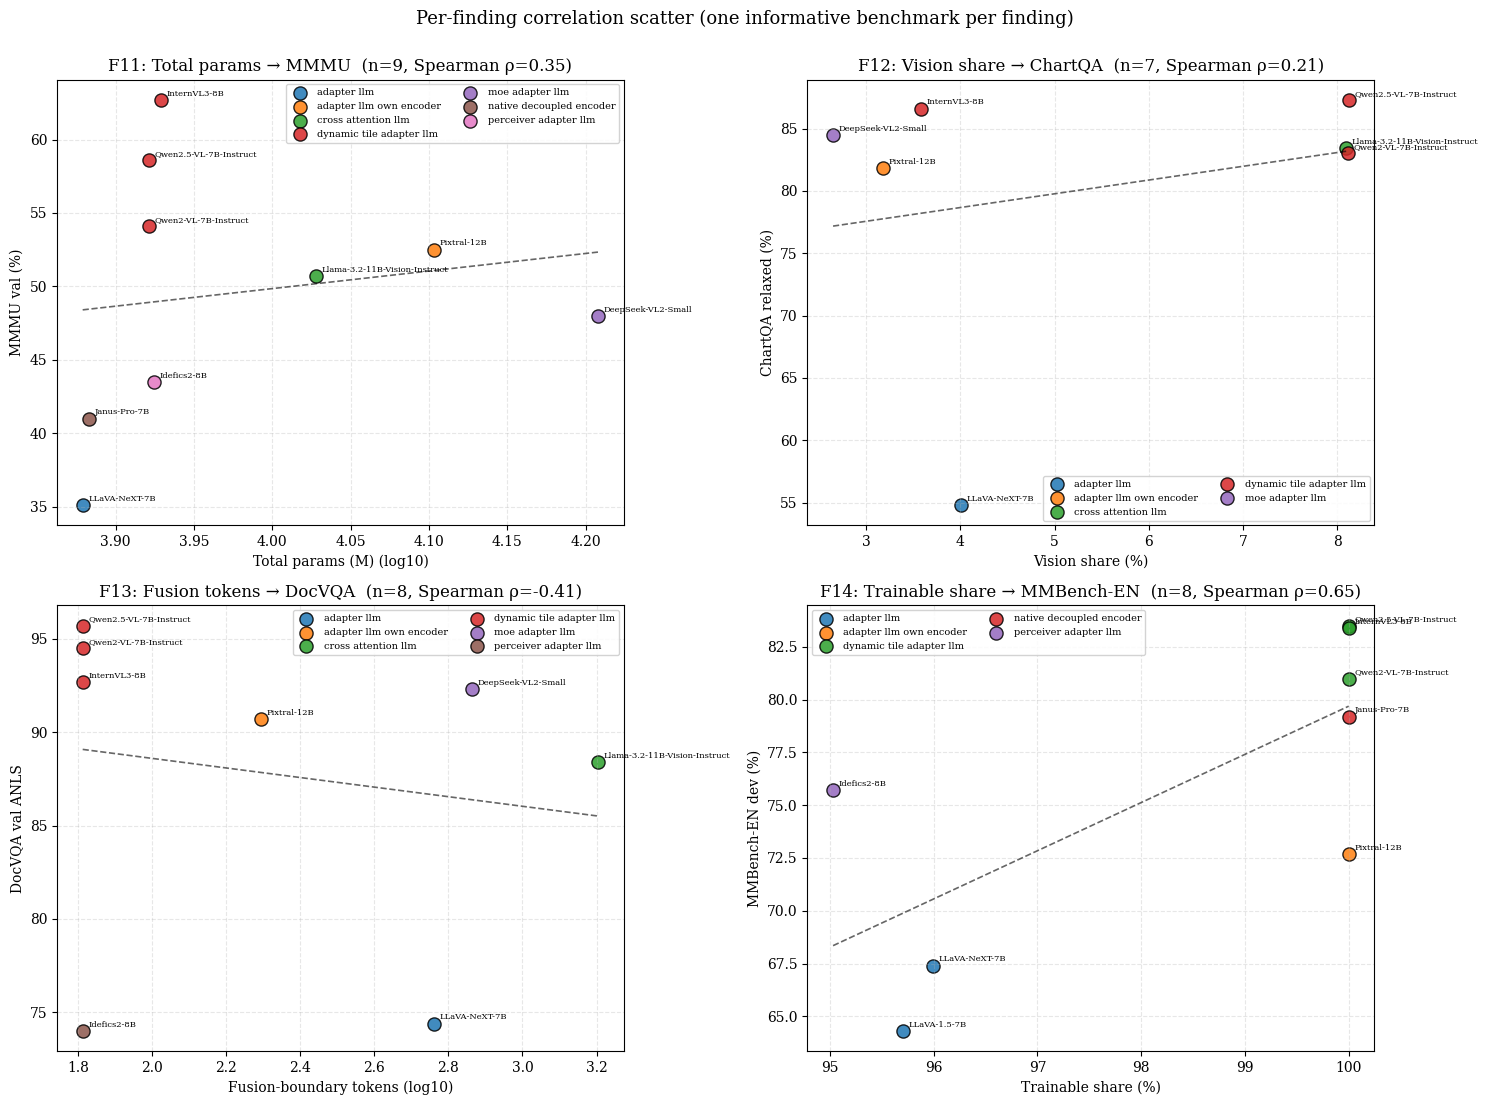

Saved: /workspace/code_active/outputs/figures/nb13_per_finding_scatter.png


In [17]:
def make_scatter(ax, joined_sub, x_col, y_col, x_label, y_label, title, log_x=False):
    sub = joined_sub[['name', 'family', x_col, y_col]].dropna(subset=[x_col, y_col])
    if len(sub) < 3:
        ax.text(0.5, 0.5, f'insufficient data (n={len(sub)})', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title)
        return
    families = sorted(sub['family'].unique())
    cmap = plt.get_cmap('tab10')
    color_by_fam = {f: cmap(i % 10) for i, f in enumerate(families)}
    for fam in families:
        d = sub[sub['family'] == fam]
        xs = d[x_col].astype(float).values
        ys = d[y_col].astype(float).values
        if log_x:
            xs_plot = np.log10(xs + 1)
        else:
            xs_plot = xs
        ax.scatter(xs_plot, ys, color=color_by_fam[fam], edgecolor='black', s=90, alpha=0.85, label=fam.replace('_', ' '))
        for x, y, n in zip(xs_plot, ys, d['name']):
            ax.annotate(n, (x, y), xytext=(4, 3), textcoords='offset points', fontsize=6)
    # Regression line on plotted (possibly log-x) coordinates
    xs_all = sub[x_col].astype(float).values
    ys_all = sub[y_col].astype(float).values
    xs_plot = np.log10(xs_all + 1) if log_x else xs_all
    if len(xs_plot) >= 2:
        coef = np.polyfit(xs_plot, ys_all, 1)
        xfit = np.linspace(xs_plot.min(), xs_plot.max(), 50)
        yfit = np.polyval(coef, xfit)
        ax.plot(xfit, yfit, color='black', linestyle='--', alpha=0.6, linewidth=1.2)
    rho_val = spearman(xs_all.tolist(), ys_all.tolist())
    rho_str = f'{rho_val:.2f}' if rho_val is not None else '—'
    ax.set_xlabel(x_label + (' (log10)' if log_x else ''))
    ax.set_ylabel(y_label)
    ax.set_title(f'{title}  (n={len(sub)}, Spearman ρ={rho_str})')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(fontsize=7, loc='best', framealpha=0.85, ncol=2)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
make_scatter(axes[0,0], joined, 'total_params_M', 'mmmu',
             'Total params (M)', 'MMMU val (%)', 'F11: Total params → MMMU', log_x=True)
make_scatter(axes[0,1], joined, 'vision_pct', 'chartqa',
             'Vision share (%)', 'ChartQA relaxed (%)', 'F12: Vision share → ChartQA', log_x=False)
make_scatter(axes[1,0], joined, 'fusion_tokens', 'docvqa',
             'Fusion-boundary tokens', 'DocVQA val ANLS', 'F13: Fusion tokens → DocVQA', log_x=True)
make_scatter(axes[1,1], joined, 'trainable_pct', 'mmbench_en',
             'Trainable share (%)', 'MMBench-EN dev (%)', 'F14: Trainable share → MMBench-EN', log_x=False)
plt.suptitle('Per-finding correlation scatter (one informative benchmark per finding)', y=1.00, fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nb13_per_finding_scatter.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR / "nb13_per_finding_scatter.png"}')

---
## 15. Per-finding evidence summary tables

One paragraph + one table per finding. This is the paper-ready synthesis. Each finding's table lists every benchmark + Spearman ρ + CI + interpretation.

In [18]:
# Compact per-finding summary
for finding in ['F11', 'F12', 'F13', 'F14']:
    sub = corr_df[corr_df['finding'] == finding].copy()
    if sub.empty:
        continue
    print(f'\n=== {finding} ===')
    cols = ['structural_lbl', 'benchmark', 'n', 'spearman_rho', 'spearman_ci_lo', 'spearman_ci_hi', 'status']
    print(sub[cols].to_string(index=False))


=== F11 ===
  structural_lbl  benchmark  n  spearman_rho  spearman_ci_lo  spearman_ci_hi status
Total params (M)       ai2d  7        0.6429         -0.1250          1.0000     ok
Total params (M)    chartqa  7        0.2500         -0.9608          1.0000     ok
Total params (M)     docvqa  8       -0.0476         -0.8421          0.7568     ok
Total params (M)  mathvista  7       -0.0714         -0.6471          0.8696     ok
Total params (M) mmbench_en  8        0.4524         -0.5949          1.0000     ok
Total params (M)       mmmu  9        0.3500         -0.6216          0.9450     ok
Total params (M)  seedbench  5        0.7000         -0.6667          1.0000     ok
Total params (M)      vqav2  6        0.6571          0.0000          1.0000     ok

=== F12 ===
    structural_lbl  benchmark  n  spearman_rho  spearman_ci_lo  spearman_ci_hi status
  Vision share (%)       ai2d  7        0.1071         -0.6471          1.0000     ok
  Vision share (%)    chartqa  7        0.2143

---
## 16. Caveats

Honest limitations to document in the paper:

1. **Small n.** 20 models means correlations below ~|0.45| are not statistically distinguishable from zero at α=0.05. We report bootstrap CIs to make this explicit.
2. **Missing data.** Sparsity in benchmarks.csv means some pairs have n<5. Report `insufficient_data` rather than fabricating.
3. **Reported scores are not paired evaluations.** Different papers use slightly different eval scripts, prompt templates, OCR settings, etc. The standardisation effort by VLMEvalKit and OpenCompass is imperfect.
4. **Benchmark contamination.** Recent models likely saw MMMU / MathVista training data either directly or via web-scraped pretraining mixes. Correlations reflect this contamination, not pure capability.
5. **Structural metrics confound with each other.** Total params, FLOPs, and fusion tokens all correlate with each other (bigger models often have more tokens too). The individual coefficients should be read as marginal correlations, not as causal effects.
6. **No native_fused or decoupled_vision representation in some benchmarks.** Chameleon and Janus-Pro report a smaller benchmark mix than the standard VLMs; corr analysis on benchmarks where they're absent applies only to the standard_vflh schema.

---
## 17. Save outputs

* `nb13_correlations.csv` — full long-format correlation table (64 rows: 8 structural × 8 benchmarks).
* `nb13_correlations.md` — paper-ready markdown with per-finding tables + interpretation guide.
* Figures already saved above (`nb13_correlation_heatmap.png`, `nb13_per_finding_scatter.png`).

In [19]:
csv_out = MEASUREMENT_DIR / 'nb13_correlations.csv'
md_out = MEASUREMENT_DIR / 'nb13_correlations.md'
corr_df.to_csv(csv_out, index=False)
print(f'Saved CSV: {csv_out}')

md_lines = ['# F11-F14 Architecture × Benchmark Correlations', '']
md_lines.append(f'Generated: {date.today().isoformat()}')
md_lines.append(f'Models in joined table: {len(joined)}')
md_lines.append(f'Bootstrap: 2000 samples, 95% CI')
md_lines.append(f'Primary statistic: Spearman ρ (rank-based, robust to log-scale and bounded scores)')
md_lines.append('')
md_lines.append('## Interpretation guide')
md_lines.append('- |ρ| > 0.7: strong correlation (report cautiously, always with CI)')
md_lines.append('- 0.45 < |ρ| < 0.7: moderate; useful for discussion but not a headline')
md_lines.append('- |ρ| < 0.45 OR 95% CI crosses 0: NOT a finding — report null result explicitly')
md_lines.append('- n < 3 valid points: insufficient data — return to nb12 and fill more cells')
md_lines.append('')
for finding, name in [('F11', 'Total params → benchmark'), ('F12', 'Vision-share → benchmark'),
                       ('F13', 'FLOPs / fusion-tokens → benchmark'), ('F14', 'Trainable share → benchmark')]:
    sub = corr_df[corr_df['finding'] == finding].copy()
    md_lines.append(f'## {finding} — {name}')
    md_lines.append('')
    md_lines.append('| Structural | Benchmark | n | Spearman ρ [95% CI] | Pearson r [95% CI] | p (Spearman) | Status |')
    md_lines.append('|:--|:--|--:|:--|:--|--:|:--|')
    for _, r in sub.iterrows():
        rho_s = f'{r["spearman_rho"]:.3f}' if r['spearman_rho'] is not None else '—'
        ci_s = f'[{r["spearman_ci_lo"]:.2f}, {r["spearman_ci_hi"]:.2f}]' if r['spearman_ci_lo'] is not None else ''
        r_p = f'{r["pearson_r"]:.3f}' if r['pearson_r'] is not None else '—'
        ci_p = f'[{r["pearson_ci_lo"]:.2f}, {r["pearson_ci_hi"]:.2f}]' if r['pearson_ci_lo'] is not None else ''
        p_s = f'{r["spearman_p"]:.3f}' if r['spearman_p'] is not None else '—'
        md_lines.append(f'| {r["structural_lbl"]} | {r["benchmark"]} | {r["n"]} | {rho_s} {ci_s} | {r_p} {ci_p} | {p_s} | {r["status"]} |')
    md_lines.append('')
md_out.write_text('\n'.join(md_lines), encoding='utf-8')
print(f'Saved MD:  {md_out}')

Saved CSV: /workspace/code_active/outputs/measurements/nb13_correlations.csv
Saved MD:  /workspace/code_active/outputs/measurements/nb13_correlations.md


---
## Next steps

* If F11-F14 produced clean evidence → fold the heatmap (`nb13_correlation_heatmap.png`) and the per-finding scatter (`nb13_per_finding_scatter.png`) into the paper's Results section and the per-finding tables into the Appendix.
* If the correlations are noisy → return to **notebook 12** and fill more cells in `benchmarks.csv`. The bootstrap CIs will narrow as n grows.
* Continue to **`14_generation_trajectory.ipynb`** for the 2021→2026 architectural-evolution analysis.
* Continue to **`15_bottleneck_synthesis.ipynb`** for the literature-vs-measurement cross-reference.

*End of notebook 13. The hard truth: this notebook is only as informative as nb12's data quality. Iterate.*